# 04 · Open questions from the first pass
1. What decides whether a payment is fast or slow? (R11) and why are scams slow? (N7)
2. The MQ→TN corridor (G1)
3. Beneficiary address country (P5)
4. The fat-finger transformation (N1)

In [18]:
import sys; sys.path.insert(0, '../src')
from utils import q, rule_check, savefig, export, con
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## 1. Duration is a property of the banks on the path
### H1  Each bank has its own processing delay; a payment's duration is set by which banks handle it
Test on Direct payments with a visible path (two banks, one link): how much of the variance of log10(duration) is explained by knowing the ordering bank, the beneficiary bank, or the pair?

In [19]:
con.execute('''CREATE OR REPLACE TEMP TABLE hop AS
  SELECT ROW_ID, string_split(BIC8_PATH,';')[1] b1, string_split(BIC8_PATH,';')[2] b2, TOTAL_DURATION d, log10(TOTAL_DURATION) ld, ANOMALY
  FROM f WHERE PARTICIPANT_COUNT=2 AND NOT HAS_GAP''')
r2 = q('''SELECT count(*) n, var_pop(ld) total_var,
            1 - avg(v1)/var_pop(ld)  AS r2_ordering_bank,
            1 - avg(v2)/var_pop(ld)  AS r2_beneficiary_bank,
            1 - avg(v12)/var_pop(ld) AS r2_bank_pair
     FROM (SELECT ld, pow(ld-avg(ld) OVER (PARTITION BY b1),2) v1, pow(ld-avg(ld) OVER (PARTITION BY b2),2) v2,
                  pow(ld-avg(ld) OVER (PARTITION BY b1,b2),2) v12 FROM hop)'''); export(r2,'duration_variance_explained'); r2

,n,total_var,r2_ordering_bank,r2_beneficiary_bank,r2_bank_pair
0,6008014,0.795693,0.542241,0.418024,0.985966


Caveat: many pairs have few payments, which inflates the pair R². Same test restricted to pairs with at least 30 payments:

In [20]:
q('''WITH g AS (SELECT *, count(*) OVER (PARTITION BY b1,b2) c, avg(ld) OVER (PARTITION BY b1,b2) m FROM hop)
     SELECT count(*) n, count(DISTINCT b1||b2) pairs, 1 - avg(pow(ld-m,2))/var_pop(ld) AS r2_bank_pair, sqrt(avg(pow(ld-m,2))) AS residual_sd_log10
     FROM g WHERE c>=30''')

,n,pairs,r2_bank_pair,residual_sd_log10
0,3232142,32734,0.983793,0.111066


### H2  The delay is the bank's own (same when it sends and when it receives) and delays add up along the path
Estimate one delay t(b) per bank from Direct payments by alternating least squares on d ≈ t(b1) + t(b2); then predict payments the fit never saw: 3-bank paths.

In [21]:
pm = q('SELECT b1, b2, median(d) d, count(*) n FROM hop GROUP BY ALL')
banks = pd.Index(pd.unique(pd.concat([pm.b1, pm.b2]))); t = pd.Series(pm.d.median()/2, index=banks)
for it in range(25):
    a = pm.assign(r=pm.d - pm.b2.map(t).values).groupby('b1').apply(lambda g: np.average(g.r, weights=g.n), include_groups=False)
    b = pm.assign(r=pm.d - pm.b1.map(t).values).groupby('b2').apply(lambda g: np.average(g.r, weights=g.n), include_groups=False)
    cnt1 = pm.groupby('b1').n.sum(); cnt2 = pm.groupby('b2').n.sum()
    new = (a.reindex(banks).fillna(0)*cnt1.reindex(banks).fillna(0) + b.reindex(banks).fillna(0)*cnt2.reindex(banks).fillna(0)) / (cnt1.reindex(banks).fillna(0)+cnt2.reindex(banks).fillna(0))
    t = new.clip(lower=1)
pm['pred'] = pm.b1.map(t).values + pm.b2.map(t).values
big = pm[pm.n>=30]
print('banks:', len(t), '| pairs with >=30 payments:', len(big))
print('in-sample: corr(log pred, log actual) on pair medians =', round(np.corrcoef(np.log10(big.pred), np.log10(big.d))[0,1],4))
tb = t.rename('delay_s').rename_axis('bic').reset_index(); con.register('tb', tb); export(tb,'bank_delay_estimates'); t.describe(percentiles=[.1,.25,.5,.75,.9]).round(1)

banks: 8489 | pairs with >=30 payments: 32734
in-sample: corr(log pred, log actual) on pair medians = 0.8838


count    8489.0
mean      857.7
std      1145.3
min         1.0
10%         1.0
25%        11.0
50%       241.4
75%      1457.6
90%      2568.4
max      7147.0
dtype: float64

In [22]:
val = q('''WITH x AS (SELECT ROW_ID, TOTAL_DURATION d, string_split(BIC8_PATH,';') bs, TRANSACTION_TYPE_CODE ty FROM f WHERE PARTICIPANT_COUNT=3 AND NOT HAS_GAP)
     SELECT ty, count(*) n, corr(log10(d), log10(t1.delay_s+t2.delay_s+t3.delay_s)) AS corr_log,
            median(d/(t1.delay_s+t2.delay_s+t3.delay_s)) AS median_actual_over_predicted,
            avg((d BETWEEN 0.5*(t1.delay_s+t2.delay_s+t3.delay_s) AND 2*(t1.delay_s+t2.delay_s+t3.delay_s))::int) AS share_within_factor_2
     FROM x JOIN tb t1 ON t1.bic=bs[1] JOIN tb t2 ON t2.bic=bs[2] JOIN tb t3 ON t3.bic=bs[3] GROUP BY 1'''); export(val,'duration_additive_validation'); val

,ty,n,corr_log,median_actual_over_predicted,share_within_factor_2
0,Covered,237453,0.829547,0.854089,0.497568
1,Indirect,1860262,0.931425,0.817537,0.608969


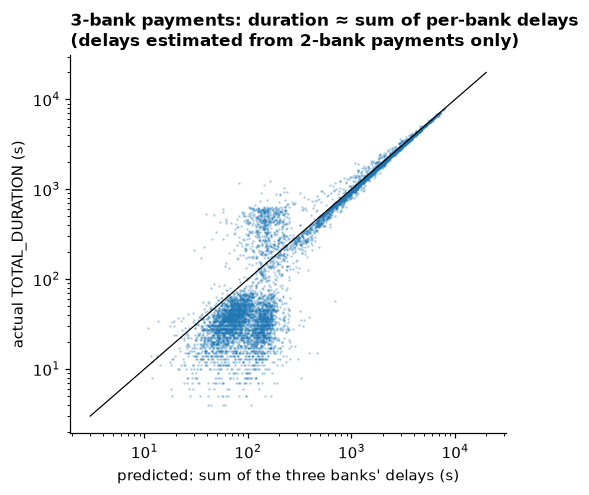

In [23]:
s = q('''WITH x AS (SELECT TOTAL_DURATION d, string_split(BIC8_PATH,';') bs FROM f WHERE PARTICIPANT_COUNT=3 AND NOT HAS_GAP AND TRANSACTION_TYPE_CODE='Indirect' USING SAMPLE 40000 ROWS)
     SELECT d, t1.delay_s+t2.delay_s+t3.delay_s pred FROM x JOIN tb t1 ON t1.bic=bs[1] JOIN tb t2 ON t2.bic=bs[2] JOIN tb t3 ON t3.bic=bs[3]''')
fig, ax = plt.subplots(figsize=(4.8,4.6)); ax.loglog(s.pred, s.d, '.', ms=1.5, alpha=.25); lim=[3,2e4]; ax.plot(lim, lim, 'k-', lw=.8)
ax.set_xlabel('predicted: sum of the three banks\' delays (s)'); ax.set_ylabel('actual TOTAL_DURATION (s)')
ax.set_title('3-bank payments: duration ≈ sum of per-bank delays\n(delays estimated from 2-bank payments only)'); savefig('D1_duration_additive_validation')

**Reading the chart.** Above about 1,000 s the points sit on the diagonal: for slow banks the sum of per-bank delays predicts the duration closely. Below about 200 s the model over-predicts: the least-squares fit is dominated by the large delays, so the estimates for fast banks (a few seconds) are imprecise. The small cloud near 500 s actual belongs to a third, medium group of banks (a few minutes). Conclusion: delay is a per-bank quantity and adds along the path; the exact per-bank values for fast banks and the combination rule for `Covered` payments (weaker fit) remain open.

### H3  Which banks are slow? Large banks are fast; among the rest about half are slow

In [24]:
vol = q('''SELECT b bic, sum(n) payments FROM (SELECT b1 b, count(*) n FROM hop GROUP BY 1 UNION ALL SELECT b2, count(*) FROM hop GROUP BY 1) GROUP BY 1''')
bk = vol.merge(tb, on='bic'); bk = bk[bk.payments>=300].copy()
bk['size_group'] = pd.qcut(bk.payments, 8, labels=False)+1
sz = bk.groupby('size_group').agg(banks=('bic','size'), min_payments=('payments','min'), max_payments=('payments','max'),
        median_delay_s=('delay_s','median'), share_slow_over_150s=('delay_s', lambda x: (x>150).mean())).reset_index(); export(sz,'bank_delay_by_size'); sz

,size_group,banks,min_payments,max_payments,median_delay_s,share_slow_over_150s
0,1,369,300.0,414.0,291.718135,0.547425
1,2,367,415.0,589.0,317.067882,0.542234
2,3,367,590.0,850.0,250.713738,0.534060
3,4,368,852.0,1217.0,203.518346,0.527174
4,5,366,1221.0,1890.0,296.592839,0.538251
5,6,368,1892.0,3115.0,153.727550,0.500000
6,7,367,3120.0,7662.0,241.272580,0.514986
7,8,368,7689.0,191802.0,24.034089,0.005435


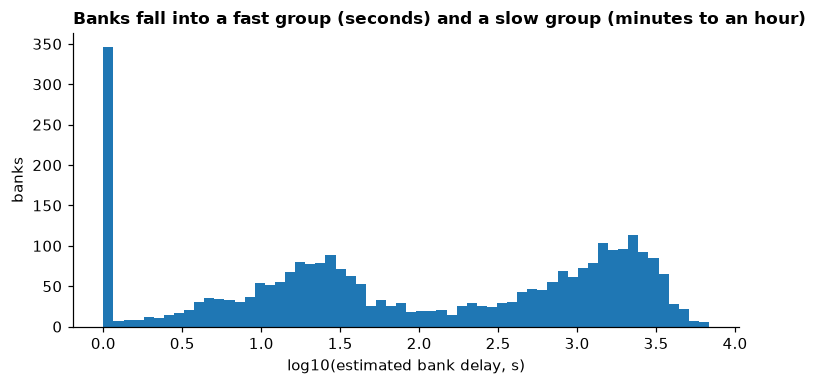

In [25]:
fig, ax = plt.subplots(figsize=(7,3.6)); ax.hist(np.log10(bk.delay_s), bins=60)
ax.set_xlabel('log10(estimated bank delay, s)'); ax.set_ylabel('banks'); ax.set_title('Banks fall into a fast group (seconds) and a slow group (minutes to an hour)'); savefig('D1_bank_delay_distribution')

### H4  Scams are slow because fraud receivers bank with slow banks (N7)

In [26]:
bk2 = bk.assign(slow=bk.delay_s>150)[['bic','slow']]; con.register('bk2', bk2)
sc = q('''SELECT ANOMALY, count(*) n, avg(k1.slow::int) AS ordering_bank_slow, avg(k2.slow::int) AS beneficiary_bank_slow
          FROM f JOIN bk2 k1 ON k1.bic=ORDERING_BIC8 JOIN bk2 k2 ON k2.bic=BENEFICIARY_BIC8
          WHERE PATH_FIRST_IS_ORD AND PATH_LAST_IS_BEN GROUP BY 1 ORDER BY 1'''); export(sc,'anomaly_bank_speed'); sc

,ANOMALY,n,ordering_bank_slow,beneficiary_bank_slow
0,ACCOUNT_REPLACEMENT_SCAM,496,0.187500,0.399194
1,CEO_SCAM,717,0.198047,0.410042
2,CUSTOMER_RECALL,264,0.178030,0.136364
3,DUPLICATE_PAYMENT,595,0.263866,0.191597
4,FAT_FINGER_MISTAKE,1640,0.191463,0.168293
5,NONE,8505880,0.190589,0.167059
6,ROMANCE_SCAM,1809,0.386954,0.442233


In [27]:
# once the banks are known, is there any extra delay left for scams? actual / predicted for direct payments
q('''SELECT ANOMALY, count(*) n, median(d/(t1.delay_s+t2.delay_s)) AS median_actual_over_predicted
     FROM hop JOIN tb t1 ON t1.bic=b1 JOIN tb t2 ON t2.bic=b2 GROUP BY 1 ORDER BY 1''')

,ANOMALY,n,median_actual_over_predicted
0,ACCOUNT_REPLACEMENT_SCAM,425,0.967806
1,CEO_SCAM,564,0.973148
2,CUSTOMER_RECALL,176,0.905697
3,DUPLICATE_PAYMENT,388,0.943892
4,FAT_FINGER_MISTAKE,1226,0.779454
5,NONE,6003843,0.811113
6,ROMANCE_SCAM,1392,0.984383


## 2. The MQ→TN corridor: a few very active sender accounts

In [28]:
q('''SELECT ORDERING_ACCOUNT, any_value(ORDERING_TYPE) ty, count(*) payments, count(DISTINCT BENEFICIARY_ACCOUNT) receivers,
            count(DISTINCT BEN_COUNTRY) receiver_countries, round(median(USD_AMOUNT),2) median_usd
     FROM f WHERE ORD_COUNTRY='MQ' GROUP BY 1 ORDER BY payments DESC LIMIT 5''')

,ORDERING_ACCOUNT,ty,payments,receivers,receiver_countries,median_usd
0,_FAKE_00E69 0N 873,B,27737,4687,138,579.92
1,_FAKE_00E69 0N 874,C,2308,614,57,82.83
2,_FAKE_000.0000069G0872,B,2015,1766,97,637.19


In [29]:
top = q('''SELECT ORDERING_TYPE, n FROM (SELECT ORDERING_ACCOUNT, any_value(ORDERING_TYPE) ORDERING_TYPE, count(*) n FROM f GROUP BY 1)''')
top = top.sort_values('n', ascending=False); tot = top.n.sum()
print('share of all payments sent by the top 100 accounts:', round(top.n.head(100).sum()/tot,3), '| top 1,000:', round(top.n.head(1000).sum()/tot,3), '| top 1%:', round(top.n.head(len(top)//100).sum()/tot,3))
print('type of the top 1,000 senders:', top.head(1000).ORDERING_TYPE.value_counts().to_dict())

share of all payments sent by the top 100 accounts: 0.094 | top 1,000: 0.272 | top 1%: 0.459
type of the top 1,000 senders: {'B': 905, 'C': 95}


## 3. Beneficiary address country
The ordering address country always equals the ordering bank country. For beneficiaries it almost never does. Is it random, or a fixed mapping?

In [30]:
rule_check('beneficiary account -> a single address country', 'n=1', table="(SELECT count(DISTINCT BEN_DETAILS_COUNTRY) n FROM f WHERE BEN_DETAILS_COUNTRY IS NOT NULL GROUP BY BENEFICIARY_ACCOUNT)")

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,beneficiary account -> a single address country,1758638,1758638.0,100.0,0.0


In [31]:
m = q('''SELECT BEN_COUNTRY, BEN_DETAILS_COUNTRY, count(*) n FROM f WHERE BEN_DETAILS_COUNTRY IS NOT NULL GROUP BY 1,2''')
m['share'] = m.n/m.groupby('BEN_COUNTRY').n.transform('sum'); m = m.sort_values(['BEN_COUNTRY','n'], ascending=[True,False])
topm = m.groupby('BEN_COUNTRY').head(3); big = m.groupby('BEN_COUNTRY').n.sum().nlargest(8).index
print('share of payments covered by the top-3 address countries of each bank country: median', round(m.groupby('BEN_COUNTRY').share.apply(lambda s: s.head(3).sum()).median(),3))
export(topm[topm.BEN_COUNTRY.isin(big)],'party_ben_address_mapping')

share of payments covered by the top-3 address countries of each bank country: median 0.752


,BEN_COUNTRY,BEN_DETAILS_COUNTRY,n,share
2055,CH,UA,337750,0.667242
2110,CH,CN,33786,0.066746
2119,CH,IN,11463,0.022646
2095,CN,PK,26527,0.125296
2091,CN,NG,23388,0.110470
2143,CN,RU,14395,0.067993
2061,DE,MX,162794,0.508517
9,DE,MY,51629,0.161273
90,DE,CN,20469,0.063939
18,FR,KP,75088,0.219247


In [32]:
# does the address country depend on the SENDER side instead? (e.g. beneficiary's nationality follows a migration corridor)
q('''SELECT count(*) n, avg((BEN_DETAILS_COUNTRY=ORD_COUNTRY)::int) eq_ordering_bank_country,
            avg((BEN_DETAILS_COUNTRY=BEN_COUNTRY)::int) eq_beneficiary_bank_country FROM f WHERE BEN_DETAILS_COUNTRY IS NOT NULL''')

,n,eq_ordering_bank_country,eq_beneficiary_bank_country
0,6107358,0.014463,0.009796


## 4. Fat-finger: is the amount a normal amount with the decimal separator moved?
If the separator moves right by 2+ places, a USD amount ends in .00; if it moves by 1, the last cent digit is 0. Test on USD payments only (other currencies are converted, which scrambles the digits).

In [33]:
q('''SELECT ANOMALY, count(*) n,
            avg((round(USD_AMOUNT*100)::bigint % 100 = 0)::int) AS ends_in_00,
            avg((round(USD_AMOUNT*100)::bigint % 10 = 0)::int)  AS last_cent_digit_0,
            avg((round(USD_AMOUNT*100)::bigint % 10 <> 0)::int) AS has_two_real_decimals
     FROM f WHERE CURRENCY_CODE='USD' AND ANOMALY IN ('NONE','FAT_FINGER_MISTAKE') GROUP BY 1''')

,ANOMALY,n,ends_in_00,last_cent_digit_0,has_two_real_decimals
0,FAT_FINGER_MISTAKE,316,0.775316,0.886076,0.113924
1,NONE,1702039,0.386362,0.442492,0.557508


1706 fat-finger payments from senders with 20+ normal payments
shift
(-9.0, -1.0]    0.168
(-1.0, -0.5]    0.033
(-0.5, 0.5]     0.066
(0.5, 1.0]      0.065
(1.0, 2.0]      0.175
(2.0, 3.0]      0.200
(3.0, 4.0]      0.164
(4.0, 9.0]      0.129
Name: proportion, dtype: float64


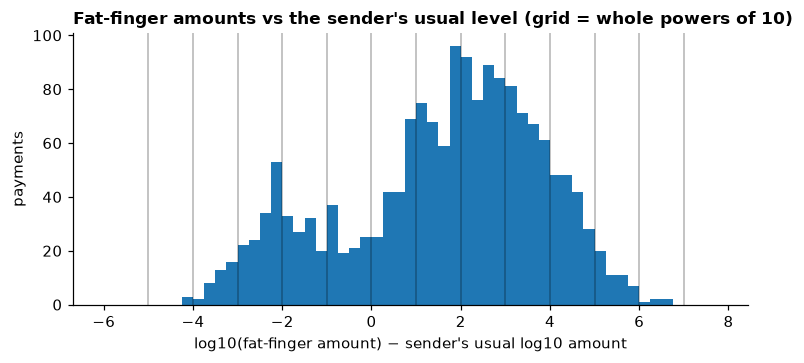

In [34]:
# compare with the sender's own usual amount: is the ratio close to a whole power of 10?
r = q('''WITH u AS (SELECT ORDERING_ACCOUNT, median(LOG10_USD) m, count(*) c FROM f WHERE NOT IS_ANOMALY GROUP BY 1 HAVING count(*)>=20)
         SELECT a.LOG10_USD - u.m AS shift FROM f a JOIN u USING (ORDERING_ACCOUNT) WHERE a.ANOMALY='FAT_FINGER_MISTAKE' ''')
fig, ax = plt.subplots(figsize=(7,3.4)); ax.hist(r['shift'], bins=np.arange(-6,8,0.25))
for k in range(-5,8): ax.axvline(k, color='k', lw=.3)
ax.set_xlabel("log10(fat-finger amount) − sender's usual log10 amount"); ax.set_ylabel('payments')
ax.set_title('Fat-finger amounts vs the sender\'s usual level (grid = whole powers of 10)'); savefig('D4_fat_finger_vs_sender_usual')
print(len(r), 'fat-finger payments from senders with 20+ normal payments'); print(pd.cut(r['shift'], [-9,-1,-.5,.5,1,2,3,4,9]).value_counts(sort=False, normalize=True).round(3))